# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Nur Ihsan
- **Email:** nurihsanazhari@gmail.com
- **ID Dicoding:** nurihsannn

## Menentukan Pertanyaan Bisnis
- **Pertanyaan 1 (Konsentrasi Kota):** Di 10 kota (city) manakah terdapat pelanggan unik terbanyak beserta persentase kontribusinya terhadap total pelanggan unik pada seluruh data historis Olist, sehingga tim logistik dapat memprioritaskan hub distribusi pada perencanaan kuartal berikutnya?
  - *Specific*: Fokus pada 10 kota dengan pelanggan unik terbanyak.
  - *Measurable*: Jumlah pelanggan unik dan persentase kontribusi terhadap total pelanggan unik.
  - *Action-Oriented*: Hasilnya menentukan urutan prioritas lokasi hub/gudang distribusi.
  - *Relevant*: Hub yang dekat dengan konsentrasi pelanggan membantu mempercepat pengiriman e-commerce.
  - *Time-bound*: Data historis seluruh periode dataset, untuk keputusan perencanaan kuartal berikutnya.

- **Pertanyaan 2 (Konsentrasi Negara Bagian):** Bagaimana perbandingan jumlah dan persentase pelanggan unik di 5 negara bagian (state) teratas pada seluruh data historis Olist, sehingga tim marketing dapat membagi budget promosi secara proporsional dengan ukuran pasar tiap wilayah pada perencanaan kuartal berikutnya?
  - *Specific*: Fokus pada 5 negara bagian dengan pelanggan unik terbanyak.
  - *Measurable*: Jumlah pelanggan unik dan persentase kontribusinya.
  - *Action-Oriented*: Tim marketing dapat membagi persentase budget ads sesuai ukuran pasar tiap state.
  - *Relevant*: Berkaitan langsung dengan alokasi dana kampanye pemasaran.
  - *Time-bound*: Data historis seluruh periode dataset, untuk perencanaan kuartal berikutnya.

## Import Semua Packages/Library yang Digunakan

In [14]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## Data Wrangling

### Gathering Data

In [15]:
customers_df = pd.read_csv("olist_customers_dataset.csv")
customers_df.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


**Insight:**
- Tabel `customers` berisi 5 kolom: `customer_id`, `customer_unique_id`, `customer_zip_code_prefix`, `customer_city`, dan `customer_state`.
- `customer_id` bersifat unik **per pesanan**, sedangkan `customer_unique_id` mengidentifikasi **orang yang sama** lintas pesanan. Karena itu, untuk menghitung "pelanggan", kolom yang dipakai adalah `customer_unique_id`.

### Assessing Data

In [16]:
print("--- Info Dataset ---")
customers_df.info()

print("\n--- Missing Values ---")
print(customers_df.isna().sum())

print(f"\nBaris duplikat persis: {customers_df.duplicated().sum()}")
print(f"Jumlah customer_id unik        : {customers_df['customer_id'].nunique()}")
print(f"Jumlah customer_unique_id unik : {customers_df['customer_unique_id'].nunique()}")
print(f"Baris dengan customer_unique_id berulang: {customers_df['customer_unique_id'].duplicated().sum()}")

--- Info Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB

--- Missing Values ---
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

Baris duplikat persis: 0
Jumlah customer_id unik        : 99441
Jumlah customer_unique_id unik : 96096
Baris dengan customer_unique_id berulang: 3345


In [17]:
lokasi = customers_df.groupby("customer_unique_id").agg(
    n_kota=("customer_city", "nunique"),
    n_state=("customer_state", "nunique"),
)
print(f"customer_unique_id dengan >1 kota  : {(lokasi['n_kota'] > 1).sum()}")
print(f"customer_unique_id dengan >1 state : {(lokasi['n_state'] > 1).sum()}")

panjang_zip = customers_df["customer_zip_code_prefix"].astype(str).str.len()
print("\nPanjang digit customer_zip_code_prefix:")
print(panjang_zip.value_counts())

print("\nContoh nama kota (format asli):", customers_df["customer_city"].head(5).tolist())
print("Jumlah state unik:", customers_df["customer_state"].nunique())

customer_unique_id dengan >1 kota  : 122
customer_unique_id dengan >1 state : 39

Panjang digit customer_zip_code_prefix:
customer_zip_code_prefix
5    75446
4    23995
Name: count, dtype: int64

Contoh nama kota (format asli): ['franca', 'sao bernardo do campo', 'sao paulo', 'mogi das cruzes', 'campinas']
Jumlah state unik: 27


**Insight & Identifying Problem:**
- **Missing value:** tidak ada. Seluruh 99.441 baris terisi lengkap di semua kolom.
- **Duplicate data:** tidak ada baris yang duplikat persis. Namun terdapat 99.441 `customer_id` tetapi hanya 96.096 `customer_unique_id`, artinya 3.345 baris adalah *repeat order* oleh pelanggan yang sama. Jika tidak ditangani, pelanggan yang sama akan terhitung lebih dari sekali. **Solusi:** hapus duplikasi berdasarkan `customer_unique_id`.
- **Inconsistent value (lokasi):** 122 `customer_unique_id` tercatat di lebih dari satu kota, dan 39 di antaranya di lebih dari satu state (pelanggan pindah alamat atau memakai alamat kirim berbeda). Tabel tidak punya kolom waktu sehingga alamat terbaru tidak dapat ditentukan. **Solusi:** pertahankan catatan pertama; dampaknya sangat kecil (0,13% dari pelanggan unik).
- **Invalid/inconsistent value (format):** 23.995 baris `customer_zip_code_prefix` hanya 4 digit karena angka nol di depan hilang saat disimpan sebagai integer. **Solusi:** ubah ke string dan lengkapi menjadi 5 digit (`zfill(5)`). Kolom ini tidak dipakai langsung dalam analisis, tetapi tetap diperbaiki agar datanya valid.
- **Inconsistent value (format kota):** nama kota seluruhnya huruf kecil dan tanpa aksen (mis. `sao paulo`). **Solusi:** standarkan menjadi *Title Case* agar label grafik lebih rapi.
- **Keterbatasan data:** tidak ada kolom tanggal, sehingga analisis tidak dapat difilter per periode.

### Cleaning Data

In [18]:
print(f"Total baris sebelum dibersihkan: {customers_df.shape[0]}")

customers_df = customers_df.drop_duplicates(subset="customer_unique_id", keep="first").copy()

customers_df["customer_zip_code_prefix"] = (
    customers_df["customer_zip_code_prefix"].astype(str).str.zfill(5)
)

customers_df["customer_city"] = customers_df["customer_city"].str.title()

print(f"Total baris sesudah dibersihkan: {customers_df.shape[0]}")
print(f"Duplikasi customer_unique_id tersisa: {customers_df['customer_unique_id'].duplicated().sum()}")
print(f"Kode pos bukan 5 digit tersisa: {(customers_df['customer_zip_code_prefix'].str.len() != 5).sum()}")
customers_df.head()

Total baris sebelum dibersihkan: 99441
Total baris sesudah dibersihkan: 96096
Duplikasi customer_unique_id tersisa: 0
Kode pos bukan 5 digit tersisa: 0


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,Franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,09790,Sao Bernardo Do Campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,01151,Sao Paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,08775,Mogi Das Cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,Campinas,SP


**Insight:** setelah cleaning, data berisi 96.096 baris dan setiap baris mewakili satu pelanggan unik. Format kode pos dan nama kota sudah seragam.

## Exploratory Data Analysis (EDA)

In [19]:
total_customers = customers_df["customer_unique_id"].nunique()

top_cities = (
    customers_df.groupby("customer_city")["customer_unique_id"].nunique()
    .sort_values(ascending=False).reset_index(name="customer_count")
)
top_cities["percentage (%)"] = round(top_cities["customer_count"] / total_customers * 100, 2)

top_states = (
    customers_df.groupby("customer_state")["customer_unique_id"].nunique()
    .sort_values(ascending=False).reset_index(name="customer_count")
)
top_states["percentage (%)"] = round(top_states["customer_count"] / total_customers * 100, 2)

print(f"Total pelanggan unik: {total_customers:,}")
print(f"Jumlah kota: {customers_df['customer_city'].nunique():,} | Jumlah state: {customers_df['customer_state'].nunique()}")

print("\n--- Top 10 Kota ---")
display(top_cities.head(10))

print("\n--- Top 5 Negara Bagian ---")
display(top_states.head(5))

top10_sum = top_cities.head(10)["customer_count"].sum()
print(f"\nTotal 10 kota teratas: {top10_sum:,} pelanggan ({top10_sum / total_customers * 100:.2f}%)")
sp_rj = top_cities.head(2)["customer_count"].sum()
print(f"Sao Paulo + Rio De Janeiro: {sp_rj:,} pelanggan ({sp_rj / total_customers * 100:.2f}%)")
print(f"Rasio Sao Paulo : Rio De Janeiro = {top_cities.loc[0, 'customer_count'] / top_cities.loc[1, 'customer_count']:.2f}x")
top5_sum = top_states.head(5)["customer_count"].sum()
print(f"Total 5 negara bagian teratas: {top5_sum:,} pelanggan ({top5_sum / total_customers * 100:.2f}%)")
top3_sum = top_states.head(3)["customer_count"].sum()
print(f"SP + RJ + MG: {top3_sum:,} pelanggan ({top3_sum / total_customers * 100:.2f}%)")

Total pelanggan unik: 96,096
Jumlah kota: 4,118 | Jumlah state: 27

--- Top 10 Kota ---


,customer_city,customer_count,percentage (%)
0,Sao Paulo,14971,15.58
1,Rio De Janeiro,6611,6.88
2,Belo Horizonte,2671,2.78
3,Brasilia,2066,2.15
4,Curitiba,1462,1.52
5,Campinas,1397,1.45
6,Porto Alegre,1326,1.38
7,Salvador,1208,1.26
8,Guarulhos,1151,1.20
9,Sao Bernardo Do Campo,908,0.94



--- Top 5 Negara Bagian ---


,customer_state,customer_count,percentage (%)
0,SP,40295,41.93
1,RJ,12377,12.88
2,MG,11255,11.71
3,RS,5277,5.49
4,PR,4882,5.08



Total 10 kota teratas: 33,771 pelanggan (35.14%)
Sao Paulo + Rio De Janeiro: 21,582 pelanggan (22.46%)
Rasio Sao Paulo : Rio De Janeiro = 2.26x
Total 5 negara bagian teratas: 74,086 pelanggan (77.10%)
SP + RJ + MG: 63,927 pelanggan (66.52%)


**Insight**
- **Berdasarkan kota:** dari 96.096 pelanggan unik, Sao Paulo memiliki basis terbesar, yaitu 14.971 pelanggan (15,58%), sekitar 2,3 kali Rio De Janeiro di urutan kedua (6.611; 6,88%). Belo Horizonte di urutan ketiga memiliki 2.671 pelanggan (2,78%). Tujuh kota berikutnya (Brasilia, Curitiba, Campinas, Porto Alegre, Salvador, Guarulhos, Sao Bernardo Do Campo) berkisar 908-2.066 pelanggan (0,94%-2,15%). Sepuluh kota teratas menyumbang 33.771 pelanggan (35,14%).
- **Berdasarkan negara bagian:** SP mendominasi dengan 40.295 pelanggan (41,93%), disusul RJ 12.377 (12,88%), MG 11.255 (11,71%), RS 5.277 (5,49%), dan PR 4.882 (5,08%). Lima negara bagian teratas mencakup 74.086 pelanggan (77,10%), dan tiga teratas saja 66,52%.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Di 10 kota (city) manakah terdapat pelanggan unik terbanyak dan berapa persentase kontribusinya?

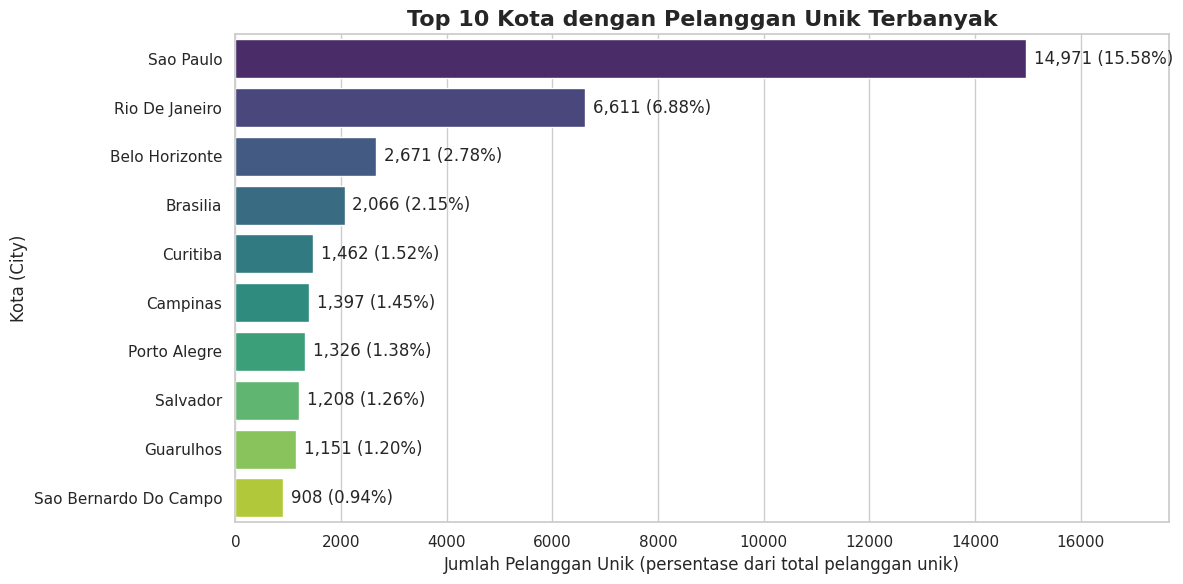

In [20]:
top10_cities = top_cities.head(10)

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    x="customer_count", y="customer_city", hue="customer_city",
    data=top10_cities, palette="viridis", legend=False,
)
for i, (cnt, pct) in enumerate(zip(top10_cities["customer_count"], top10_cities["percentage (%)"])):
    ax.text(cnt + top10_cities["customer_count"].max() * 0.01, i, f"{cnt:,} ({pct:.2f}%)", va="center")
ax.set_xlim(0, top10_cities["customer_count"].max() * 1.18)
plt.title("Top 10 Kota dengan Pelanggan Unik Terbanyak", fontsize=16, fontweight="bold")
plt.xlabel("Jumlah Pelanggan Unik (persentase dari total pelanggan unik)", fontsize=12)
plt.ylabel("Kota (City)", fontsize=12)
plt.tight_layout()
plt.show()

**Insight**

Sao Paulo berada jauh di depan dengan 14.971 pelanggan unik (15,58%), sekitar 2,3 kali Rio De Janeiro (6.611; 6,88%) dan sekitar 5,6 kali Belo Horizonte (2.671; 2,78%). Kota ke-4 sampai ke-10 (Brasilia 2.066, Curitiba 1.462, Campinas 1.397, Porto Alegre 1.326, Salvador 1.208, Guarulhos 1.151, Sao Bernardo Do Campo 908) berada di rentang 0,94%-2,15% dengan selisih antarkota yang relatif kecil, sehingga tidak ada kota di luar tiga teratas yang menonjol. Kesepuluh kota ini bersama-sama mewakili 35,14% pelanggan, sehingga 64,86% pelanggan lainnya tersebar di kota-kota di luar Top 10. Untuk prioritas hub, Sao Paulo dan Rio De Janeiro (gabungan 22,46%) adalah kandidat utama, diikuti Belo Horizonte.

### Pertanyaan 2: Bagaimana perbandingan distribusi pelanggan (jumlah dan persentase) di 5 negara bagian (state) teratas?

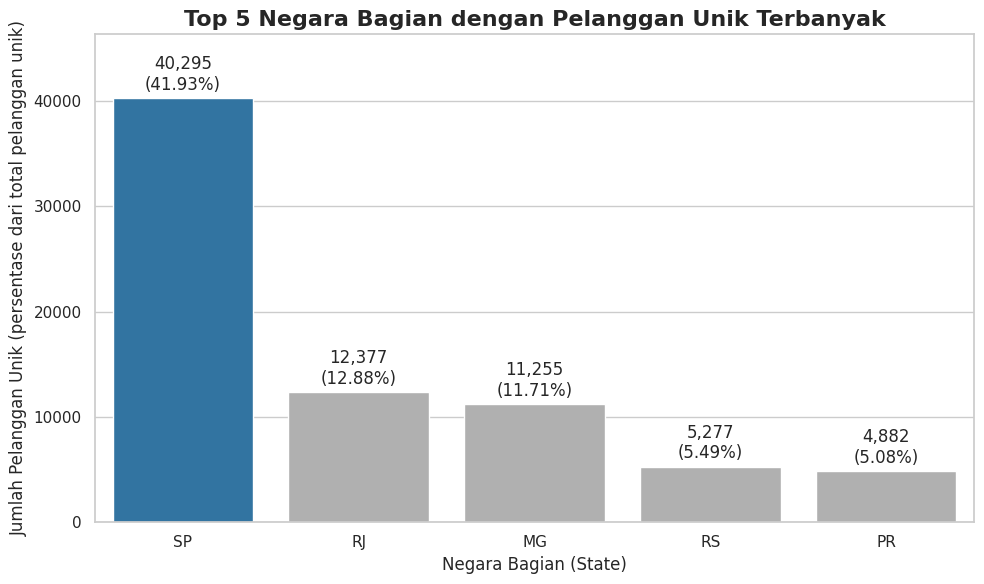

In [21]:
top5_states = top_states.head(5)
warna = ["#1f77b4" if i == 0 else "#b0b0b0" for i in range(5)]

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    x="customer_state", y="customer_count", hue="customer_state",
    data=top5_states, palette=warna, legend=False,
)
for i, (cnt, pct) in enumerate(zip(top5_states["customer_count"], top5_states["percentage (%)"])):
    ax.text(i, cnt + top5_states["customer_count"].max() * 0.01, f"{cnt:,}\n({pct:.2f}%)", ha="center", va="bottom")
ax.set_ylim(0, top5_states["customer_count"].max() * 1.15)
plt.title("Top 5 Negara Bagian dengan Pelanggan Unik Terbanyak", fontsize=16, fontweight="bold")
plt.xlabel("Negara Bagian (State)", fontsize=12)
plt.ylabel("Jumlah Pelanggan Unik (persentase dari total pelanggan unik)", fontsize=12)
plt.tight_layout()
plt.show()

**Insight**

SP memiliki 40.295 pelanggan (41,93%), sekitar 3,3 kali RJ (12.377; 12,88%) dan sekitar 3,6 kali MG (11.255; 11,71%). RS (5.277; 5,49%) dan PR (4.882; 5,08%) berukuran hampir sama dan masing-masing kurang dari separuh MG. Kelima negara bagian ini mencakup 77,10% pelanggan, dan SP+RJ+MG saja 66,52%. Jika budget promosi dibagi proporsional dengan ukuran pasar, tiga negara bagian teratas layak menerima porsi terbesar, sedangkan RS dan PR berada di tier kedua dengan porsi yang kurang lebih setara.

## Analisis Lanjutan

Dua teknik clustering tanpa machine learning diterapkan agar temuan lebih kaya: **manual grouping** (pengelompokan state ke region makro Brazil berdasarkan pembagian resmi IBGE) dan **binning** (pengelompokan kota berdasarkan ukuran basis pelanggan dengan `pd.cut`).

### Manual Grouping: Segmentasi Region Makro

State yang belum terpetakan: 0


,region_cluster,customer_count,percentage (%)
0,Sudeste,65890,68.57
1,Sul,13688,14.24
2,Nordeste,9133,9.50
3,Centro-Oeste,5592,5.82
4,Norte,1793,1.87


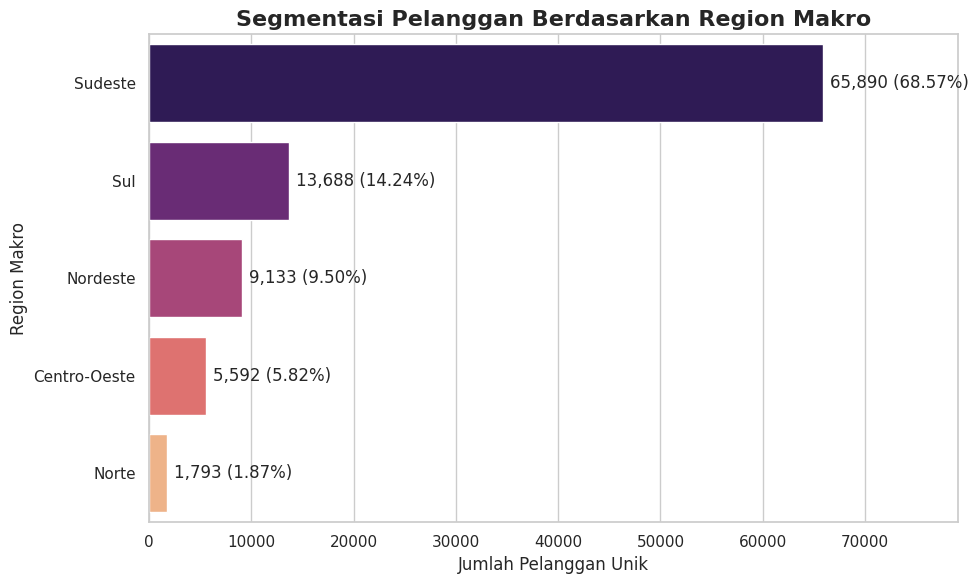

In [22]:
brazil_regions = {
    "AM": "Norte", "RR": "Norte", "AP": "Norte", "PA": "Norte", "TO": "Norte", "RO": "Norte", "AC": "Norte",
    "MA": "Nordeste", "PI": "Nordeste", "CE": "Nordeste", "RN": "Nordeste", "PE": "Nordeste",
    "PB": "Nordeste", "SE": "Nordeste", "AL": "Nordeste", "BA": "Nordeste",
    "MT": "Centro-Oeste", "MS": "Centro-Oeste", "GO": "Centro-Oeste", "DF": "Centro-Oeste",
    "SP": "Sudeste", "RJ": "Sudeste", "ES": "Sudeste", "MG": "Sudeste",
    "PR": "Sul", "RS": "Sul", "SC": "Sul",
}
customers_df["region_cluster"] = customers_df["customer_state"].map(brazil_regions)
print("State yang belum terpetakan:", customers_df["region_cluster"].isna().sum())

region_counts = (
    customers_df.groupby("region_cluster")["customer_unique_id"].nunique()
    .sort_values(ascending=False).reset_index(name="customer_count")
)
region_counts["percentage (%)"] = round(region_counts["customer_count"] / total_customers * 100, 2)
display(region_counts)

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    x="customer_count", y="region_cluster", hue="region_cluster",
    data=region_counts, palette="magma", legend=False,
)
for i, (cnt, pct) in enumerate(zip(region_counts["customer_count"], region_counts["percentage (%)"])):
    ax.text(cnt + region_counts["customer_count"].max() * 0.01, i, f"{cnt:,} ({pct:.2f}%)", va="center")
ax.set_xlim(0, region_counts["customer_count"].max() * 1.2)
plt.title("Segmentasi Pelanggan Berdasarkan Region Makro", fontsize=16, fontweight="bold")
plt.xlabel("Jumlah Pelanggan Unik")
plt.ylabel("Region Makro")
plt.tight_layout()
plt.show()

**Insight**

Region Sudeste (Tenggara) berkontribusi 68,57% pelanggan (65.890), jauh di atas Sul 14,24% (13.688), Nordeste 9,50% (9.133), Centro-Oeste 5,82% (5.592), dan Norte 1,87% (1.793). Angka 68,57% mencakup ES (1.963; 2,04%) selain SP, RJ, dan MG yang gabungannya 66,52%. Segmentasi ini menguatkan Pertanyaan 1 dan 2: pasar sangat terkonsentrasi di Tenggara, sedangkan Norte adalah region dengan pelanggan paling sedikit.

### Binning: Segmentasi Kota Berdasarkan Ukuran Basis Pelanggan

,city_tier,jumlah_kota,jumlah_pelanggan,% kota,% pelanggan
0,1-10,3251,9842,78.95,10.24
1,11-50,608,13400,14.76,13.94
2,51-100,127,9076,3.08,9.44
3,101-1000,123,30915,2.99,32.17
4,>1000,9,32863,0.22,34.20


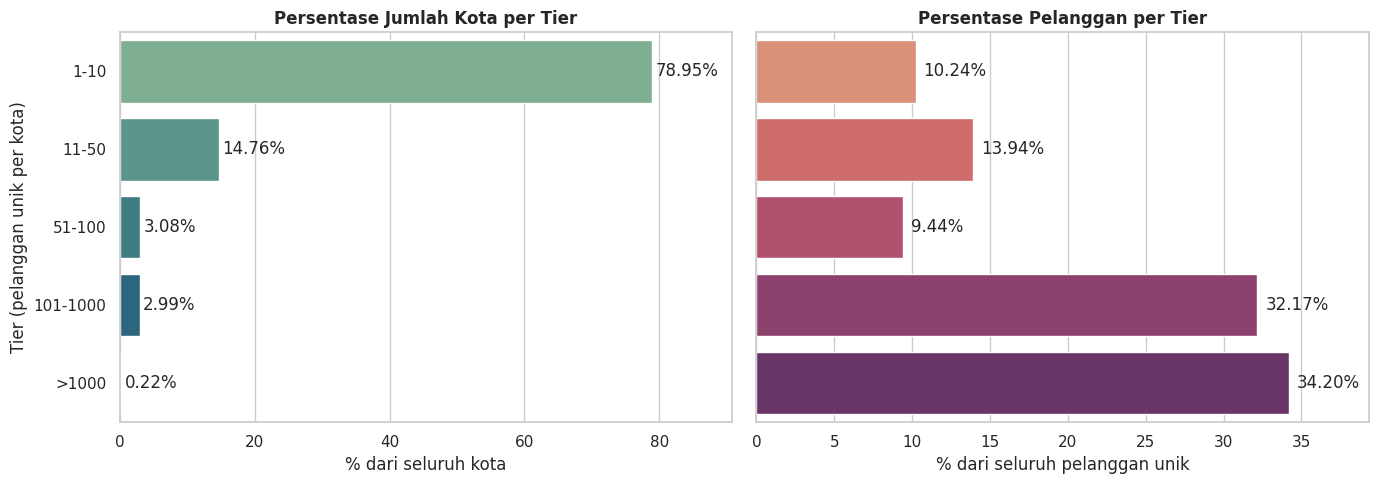

In [23]:
bins = [0, 10, 50, 100, 1000, float("inf")]
labels = ["1-10", "11-50", "51-100", "101-1000", ">1000"]
top_cities["city_tier"] = pd.cut(top_cities["customer_count"], bins=bins, labels=labels)

tier_summary = top_cities.groupby("city_tier", observed=True).agg(
    jumlah_kota=("customer_city", "count"),
    jumlah_pelanggan=("customer_count", "sum"),
).reset_index()
tier_summary["city_tier"] = tier_summary["city_tier"].astype(str)
tier_summary["% kota"] = round(tier_summary["jumlah_kota"] / tier_summary["jumlah_kota"].sum() * 100, 2)
tier_summary["% pelanggan"] = round(tier_summary["jumlah_pelanggan"] / total_customers * 100, 2)
display(tier_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
sns.barplot(x="% kota", y="city_tier", hue="city_tier", data=tier_summary, palette="crest", order=labels, legend=False, ax=axes[0])
axes[0].set_title("Persentase Jumlah Kota per Tier", fontweight="bold")
axes[0].set_xlabel("% dari seluruh kota")
axes[0].set_ylabel("Tier (pelanggan unik per kota)")
sns.barplot(x="% pelanggan", y="city_tier", hue="city_tier", data=tier_summary, palette="flare", order=labels, legend=False, ax=axes[1])
axes[1].set_title("Persentase Pelanggan per Tier", fontweight="bold")
axes[1].set_xlabel("% dari seluruh pelanggan unik")
axes[1].set_ylabel("")
for ax, col in zip(axes, ["% kota", "% pelanggan"]):
    for i, lab in enumerate(labels):
        v = tier_summary.loc[tier_summary["city_tier"] == lab, col].iloc[0]
        ax.text(v + 0.5, i, f"{v:.2f}%", va="center")
    ax.set_xlim(0, tier_summary[col].max() * 1.15)
plt.tight_layout()
plt.show()

**Insight**

Distribusi kota sangat timpang. Hanya 9 kota (0,22% dari seluruh kota) yang memiliki lebih dari 1.000 pelanggan, tetapi menyumbang 34,20% pelanggan. Sebaliknya, 3.251 kota (78,95%) hanya memiliki 1-10 pelanggan dan secara total hanya 10,24% pelanggan. Artinya pasar terpusat di segelintir kota besar, sementara ribuan kota kecil membentuk *long tail* yang tersebar dan sulit dilayani dengan hub tersendiri.

## Conclusion & Recommendation

**Kesimpulan:**
- **Conclusion Pertanyaan 1:** Konsentrasi pelanggan terbesar berada di Sao Paulo (14.971 pelanggan unik; 15,58%), Rio De Janeiro (6.611; 6,88%), dan Belo Horizonte (2.671; 2,78%), disusul Brasilia, Curitiba, Campinas, Porto Alegre, Salvador, Guarulhos, dan Sao Bernardo Do Campo. Kesepuluh kota ini mewakili 35,14% pelanggan; Sao Paulo dan Rio De Janeiro saja 22,46%. Kota ke-4 sampai ke-10 berukuran mirip (0,94%-2,15%). Analisis binning menunjukkan 78,95% kota hanya memiliki 1-10 pelanggan.
- **Conclusion Pertanyaan 2:** Lima negara bagian teratas adalah SP (40.295; 41,93%), RJ (12.377; 12,88%), MG (11.255; 11,71%), RS (5.277; 5,49%), dan PR (4.882; 5,08%), total 77,10% pelanggan. SP, RJ, dan MG bersama-sama 66,52%, sedangkan RS dan PR berukuran hampir sama. Segmentasi region menunjukkan hal serupa: Sudeste 68,57%.

**Rekomendasi Action Item:**
- **Prioritas hub logistik:** jadikan Sao Paulo dan Rio De Janeiro prioritas pertama pembangunan/perluasan hub (gabungan 22,46% pelanggan), lalu Belo Horizonte sebagai tahap berikutnya. Sebelum keputusan final, lengkapi dengan data waktu dan biaya pengiriman, karena analisis ini hanya melihat jumlah pelanggan.
- **Alokasi budget promosi:** gunakan proporsi pelanggan sebagai titik awal pembagian budget: sekitar 66,5% untuk SP, RJ, dan MG, dan sekitar 10,6% untuk RS dan PR. Evaluasi dengan data biaya akuisisi dan konversi per wilayah, yang belum tersedia di dataset ini.
- **Uji region berpotensi tumbuh:** Norte (1,87%) dan Centro-Oeste (5,82%) masih kecil. Sisihkan porsi kecil budget untuk uji kampanye di sana, lalu pantau pertumbuhan pelanggannya.
- **Layani kota kecil tanpa hub:** karena 78,95% kota hanya memiliki 1-10 pelanggan, layani melalui hub regional atau kemitraan kurir, bukan hub per kota.

**Catatan keterbatasan:** dataset pelanggan tidak memuat tanggal, nilai transaksi, maupun data pengiriman, sehingga tren waktu dan nilai pelanggan tidak dapat dianalisis dari satu tabel ini.

### Menyimpan Data untuk Dashboard

In [24]:
main_df = customers_df[["customer_unique_id", "customer_city", "customer_state", "region_cluster"]]
main_df.to_csv("main_data.csv", index=False)
print(f"Sukses! main_data.csv dibuat: {main_df.shape[0]} baris.")

Sukses! main_data.csv dibuat: 96096 baris.
